# UTS Graf Sains Data: Rekomendasi RetailRocket dengan Neo4j

Nama : Grace Pinkkan Ladyna

NIM  : 24031554137

Kelas: 2024B

# 1. Tugas Pendahuluan

## 1.1 Persiapan dan Perkenalan Lingkungan

In [2]:
import neo4j, pandas, networkx, sklearn
print("neo4j:", neo4j.__version__)
print("pandas:", pandas.__version__)

neo4j: 6.4.1
pandas: 3.0.6


## 1.2 Mempelajari Penggunaan Driver Neo4j

In [1]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

URI  = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "graell21")
DB   = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j")

Terhubung ke Neo4j


In [5]:
from neo4j import GraphDatabase, RoutingControl

URI  = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "graell21")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpoint)

1. **Nama database:** `neo4j` (database default, terlihat pada parameter `database_="neo4j"` di `execute_query`).

2. **Akses lain ke database lain dalam 1 instance:** satu instance Neo4j dapat memiliki beberapa database (pada instance ini ada dua: `neo4j` dan `system`). Database lain diakses dengan menyebut namanya:
   - **Cypher:** `USE system` di awal query, atau perintah `:use nama_db` di Neo4j Query/Browser.
   - **DDL:** `CREATE DATABASE nama_db`, `SHOW DATABASES`, dan `DROP DATABASE nama_db` (dijalankan di database `system`).
   - **DML:** `USE nama_db MATCH (n) RETURN n`.
   - **Driver Python:** mengganti parameter `database_="nama_db"` pada `execute_query` atau `driver.session(database="nama_db")`.
   - **Terminal:** `cypher-shell -d nama_db`.

3. **Jenis graf pertemanan:** graf **berarah** (relasi `KNOWS` punya arah Arthur → teman), **tidak berbobot** (relasi tidak punya properti nilai), dengan satu jenis simpul (`Person`) dan satu jenis relasi (`KNOWS`). Bentuknya **bintang (star)** dengan Arthur di pusat, 4 simpul dan 3 relasi.

### Cypher Total Reset

In [6]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
    print("Database dikosongkan")

Database dikosongkan


## 1.3 Impor Data RetailRocket ke Neo4

### Cek Dataset

`events.csv` (RetailRocket) berisi **2.756.101 baris** log interaksi pengunjung toko online, dengan rentang waktu **3 Mei – 18 September 2015**. Kolom `dt` ditambahkan hanya untuk membaca `timestamp` sebagai waktu (unit milidetik).

| Kolom | Arti |
|---|---|
| `timestamp` | waktu interaksi, unix epoch dalam milidetik |
| `visitorid` | ID unik pengunjung (menjadi node `Visitor`) |
| `event` | jenis interaksi: `view`, `addtocart`, `transaction` |
| `itemid` | ID unik produk (menjadi node `Item`) |
| `transactionid` | ID transaksi, hanya terisi pada event `transaction` |

Dari `value_counts()`: `view` 2.664.312, `addtocart` 69.332, `transaction` 22.457. Data sangat timpang ke `view` (96,7%).

In [7]:
df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")
print(df.shape)
print(df.head())
print("Rentang waktu:", df.dt.min(), "sampai", df.dt.max())
print(df.event.value_counts())

(2756101, 6)
       timestamp  visitorid event  itemid  transactionid  \
0  1433221332117     257597  view  355908            NaN   
1  1433224214164     992329  view  248676            NaN   
2  1433221999827     111016  view  318965            NaN   
3  1433221955914     483717  view  253185            NaN   
4  1433221337106     951259  view  367447            NaN   

                       dt  
0 2015-06-02 05:02:12.117  
1 2015-06-02 05:50:14.164  
2 2015-06-02 05:13:19.827  
3 2015-06-02 05:12:35.914  
4 2015-06-02 05:02:17.106  
Rentang waktu: 2015-05-03 03:00:04.384000 sampai 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


### Mekanisme Session Neo4j

Koneksi dibuat dengan `GraphDatabase.driver(URI, auth=AUTH)`, lalu sesi kerja dibuka dengan `driver.session(database=DB)`. *Driver* mengelola koneksi ke server, sedangkan *session* adalah satu sesi kerja ke satu database. Contoh pada soal memakai `database="system"` (database administrasi internal), sehingga diganti `"neo4j"` karena data RetailRocket harus masuk ke database `neo4j`. Kredensial disimpan dalam variabel agar mudah diganti.

In [9]:
from neo4j import GraphDatabase

URI  = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "graell21")
DB   = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database=DB)   
print("Driver dan session siap")

Driver dan session siap


###  Query Cypher untuk Impor (import_batch)

- `UNWIND $batch AS row` memecah list baris dari Python menjadi baris yang diproses satu per satu.
- `MERGE (v:Visitor ...)` dan `MERGE (i:Item ...)` membuat node bila belum ada. Satu pengunjung atau produk selalu menjadi satu node, sehingga tidak ada duplikat.
- `CALL { ... UNION ALL ... }` memilih jenis relasi sesuai `row.event`: `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`.
- Relasi dibuat dengan `CREATE` (bukan `MERGE`) karena seorang pengunjung bisa berinteraksi dengan item yang sama berkali-kali, dan tiap kejadian punya `timestamp` sendiri.
- `create_constraints` membuat constraint `UNIQUE` pada `visitorId` dan `itemId`, sehingga ID tidak ganda dan `MERGE` lebih cepat.

In [10]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS "
                "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS "
                "FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

### Impor dengan Mekanisme Batch

CSV dibaca per **5.000 baris** (`chunksize`) dan tiap potongan dikirim ke Neo4j dalam satu transaksi (`execute_write`). Cara ini menjaga pemakaian memori tetap kecil dan mempercepat impor dibanding mengirim baris satu per satu. Untuk data penuh dibutuhkan 552 batch. Kolom `transactionid` yang kosong (NaN) diganti string kosong agar tidak menimbulkan error.

*Catatan:* peringatan `feature deprecated` dari server pada output hanya pemberitahuan bahwa sintaks `CALL` subquery tanpa *variable scope clause* akan usang. Hasil impor tidak terpengaruh.

In [11]:
csv_file_path = os.path.join("data", "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    raise SystemExit(1)

driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)  # hindari data dobel

batch_size = 5000

with driver.session(database=DB) as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = len(pd.read_csv(csv_file_path, usecols=["visitorid"]))
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

# driver.close()   # jangan dijalankan dulu, sel berikutnya masih butuh driver
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 552/552 [13:05<00:00,  1.42s/it]

Proses impor berhasil.


### Verifikasi Hasil Impor

In [15]:
# Cek hasil
rows, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS tipe, count(n) AS jumlah", database_=DB)
for r in rows:
    print(r["tipe"], r["jumlah"])

Visitor 1407580
Item 235061


In [16]:
# Cek relasinya
rows, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah", database_=DB)
for r in rows:
    print(r["relasi"], r["jumlah"])

VIEWED 2664312
ADDED_TO_CART 69332
BOUGHT 22457


# 2. Soal UTS

## 2.1 Wrangling dan EDA

### No. 1 dan 2: Filter Periode P1 dan P2

In [17]:
P1_START, P1_END = "2015-06-01", "2015-08-15"   # training
P2_START, P2_END = "2015-08-16", "2015-09-18"   # testing

# batas atas dibuat eksklusif (hari berikutnya 00:00) supaya hari terakhir ikut penuh
p1 = df[(df.dt >= P1_START) & (df.dt < "2015-08-16")].drop(columns="dt")
p2 = df[(df.dt >= P2_START) & (df.dt < "2015-09-19")].drop(columns="dt")

p1.to_csv("data/events_p1.csv", index=False)
p2.to_csv("data/events_p2.csv", index=False)

print("Baris P1:", len(p1), "| Baris P2:", len(p2))
print("Event P1:", p1.event.value_counts().to_dict())
print("Event P2:", p2.event.value_counts().to_dict())
print("Visitor P1:", p1.visitorid.nunique(), "| Visitor P2:", p2.visitorid.nunique())
print("Visitor di kedua periode:", len(set(p1.visitorid) & set(p2.visitorid)))

Baris P1: 1573886 | Baris P2: 591563
Event P1: {'view': 1521446, 'addtocart': 39504, 'transaction': 12936}
Event P2: {'view': 571194, 'addtocart': 15459, 'transaction': 4910}
Visitor P1: 817398 | Visitor P2: 330547
Visitor di kedua periode: 22142


#### Interpretasi: Filter Periode

| | P1 (training) | P2 (testing) |
|---|---|---|
| Rentang | 1 Juni – 15 Agustus 2015 (76 hari) | 16 Agustus – 18 September 2015 (34 hari) |
| Jumlah baris | 1.573.886 | 591.563 |
| Visitor unik | 817.398 | 330.547 |
| `view` | 1.521.446 (96,7%) | 571.194 (96,6%) |
| `addtocart` | 39.504 (2,5%) | 15.459 (2,6%) |
| `transaction` | 12.936 (0,8%) | 4.910 (0,8%) |

- **Pembagian temporal.** P1 untuk membangun graf (data latih) dan P2 untuk evaluasi (data uji). Pembagian berdasarkan waktu, bukan acak, sesuai kondisi nyata sistem rekomendasi: model dibangun dari masa lalu lalu diuji pada masa depan. P2 tidak dimasukkan ke graf agar tidak terjadi *data leakage*.
- **Konversi waktu.** `timestamp` dalam milidetik (`unit="ms"`, UTC). Batas atas dibuat eksklusif (hari berikutnya pukul 00:00) agar hari terakhir tercakup penuh.
- **Data yang tidak dipakai.** Data 3–31 Mei 2015 (590.652 baris) berada di luar kedua periode sehingga dibuang. P1 dan P2 bersambung tanpa celah.
- **Distribusi event timpang.** Sekitar 96,7% interaksi hanya `view`, sedangkan pembelian hanya 0,8%. Ini data *implicit feedback*, sehingga interaksi diberi bobot: `view` = 1, `addtocart` = 3, `transaction` = 5.
- **Irisan pengunjung kecil.** Hanya **22.142 visitor** (sekitar 2,7% dari visitor P1) muncul di kedua periode. Sebagian besar pengunjung P2 adalah pengunjung baru (*cold-start*), dan hanya user di irisan ini yang bisa dievaluasi pada bagian 2.2.

### Persiapan Graf P1: Cek Isi Graf

In [19]:
rows, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah", database_=DB)
for r in rows:
    print(r["relasi"], r["jumlah"])

VIEWED 2664312
ADDED_TO_CART 69332
BOUGHT 22457


### Pengosongan Graf (Bertahap)

In [20]:
total = 0
while True:
    rows, _, _ = driver.execute_query(
        "MATCH (n) WITH n LIMIT 5000 DETACH DELETE n RETURN count(*) AS c",
        database_=DB)
    c = rows[0]["c"]
    total += c
    if c == 0:
        break
print("Selesai. Total node terhapus:", total)

Selesai. Total node terhapus: 1642641


### Verifikasi Graf Kosong

In [21]:
rows, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS c", database_=DB)
print(rows[0]["c"])   # harus 0

0


### Impor Ulang dengan Data P1

In [22]:
csv_file_path = os.path.join("data", "events_p1.csv")
if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File '{csv_file_path}' tidak ditemukan!")

batch_size = 5000

with driver.session(database=DB) as session:
    create_constraints(session)

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    total_rows = len(pd.read_csv(csv_file_path, usecols=["visitorid"]))
    total_chunks = (total_rows // batch_size) + 1

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Mengimpor Batch Data: 100%|██████████| 315/315 [02:36<00:00,  2.01it/s]

Proses impor berhasil.


### Verifikasi Graf P1

In [9]:
rows, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah", database_=DB)
for r in rows:
    print(r["relasi"], r["jumlah"])

VIEWED 1521446
ADDED_TO_CART 39504
BOUGHT 12936


### No. 3: Komposisi Subgraph

~~~cypher
MATCH (n) RETURN labels(n)[0] AS tipe, count(n) AS jumlah
~~~

`MATCH (n)` mencocokkan semua simpul, `labels(n)[0]` mengambil label simpul, dan `count(n)` yang dipasangkan dengan `labels(n)[0]` pada `RETURN` otomatis dikelompokkan per label (seperti `GROUP BY` di SQL).

~~~cypher
MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah
~~~

`MATCH ()-[r]->()` mencocokkan semua relasi berarah, dan `type(r)` mengambil nama jenis relasinya. Kedua query dijalankan dari Python lewat `driver.execute_query`.

In [10]:
rows, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS tipe, count(n) AS jumlah", database_=DB)
df_nodes = pd.DataFrame([dict(r) for r in rows])
print(df_nodes)

rows, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah", database_=DB)
df_rels = pd.DataFrame([dict(r) for r in rows])
print(df_rels)

      tipe  jumlah
0  Visitor  817398
1     Item  184978
          relasi   jumlah
0         VIEWED  1521446
1  ADDED_TO_CART    39504
2         BOUGHT    12936


#### Interpretasi: Komposisi Subgraph P1

| Jenis simpul | Jumlah |
|---|---|
| `Visitor` | 817.398 |
| `Item` | 184.978 |
| **Total simpul** | **1.002.376** |



| Jenis relasi | Jumlah |
|---|---|
| `VIEWED` | 1.521.446 |
| `ADDED_TO_CART` | 39.504 |
| `BOUGHT` | 12.936 |
| **Total relasi** | **1.573.886** |

- Graf berbentuk **bipartit berarah**: semua relasi mengalir dari `Visitor` ke `Item`, dengan tiga jenis relasi.
- Jumlah `Visitor` sekitar **4,4 kali** jumlah `Item`.
- Rata-rata hanya **1,9 interaksi per visitor** (1.573.886 / 817.398). Graf sangat jarang (*sparse*), dan ini sudah menjadi petunjuk bagi eksplorasi VSM berikutnya.
- Jumlah `Visitor` (817.398) sama dengan visitor unik P1 pada hasil filter, dan jumlah relasi sama dengan jumlah baris `events_p1.csv`, sehingga impor terbukti benar.

### No. 4 dan 5: Vector Space Modelling (VSM)

#### Pembentukan Matriks User × Item

Relasi ditarik dari Neo4j dan digabung per pasangan (visitor, item) dengan bobot `view` = 1, `addtocart` = 3, `transaction` = 5. Pasangan unik menjadi sel matriks $M$ berbentuk **user × item** dalam format sparse (`csr_matrix`).

In [2]:
from scipy.sparse import csr_matrix

rows, _, _ = driver.execute_query("""
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i,
       sum(CASE type(r) WHEN 'VIEWED' THEN 1
                        WHEN 'ADDED_TO_CART' THEN 3
                        ELSE 5 END) AS w
""", database_=DB)
E = pd.DataFrame([dict(r) for r in rows])
print(E.shape)
print(E.head())

(1227918, 3)
         u       i  w
0   350566  215904  1
1   302835  215904  1
2   180613  215904  2
3  1054686  215904  1
4   794733  215904  1


In [3]:
u_cat = E.u.astype("category")
i_cat = E.i.astype("category")
users = u_cat.cat.categories
items = i_cat.cat.categories

M = csr_matrix((E.w.values.astype(float),
                (u_cat.cat.codes.values, i_cat.cat.codes.values)),
               shape=(len(users), len(items)))

print("Shape M (user x item):", M.shape)
print("nnz:", M.nnz)
print("Density:", M.nnz / (M.shape[0] * M.shape[1]))

Shape M (user x item): (817398, 184978)
nnz: 1227918
Density: 8.12111602947339e-06


#### Interpretasi: Matriks User × Item

| Besaran | Nilai |
|---|---|
| Shape $M$ | 817.398 × 184.978 |
| Sel terisi (nnz) | 1.227.918 |
| Density | 8,12 × 10⁻⁶ (sekitar 0,0008%) |

- nnz (1.227.918) lebih kecil daripada jumlah relasi (1.573.886) karena interaksi berulang pada pasangan visitor-item yang sama digabung menjadi satu sel dengan bobot dijumlahkan (345.968 interaksi berulang).
- Hanya sekitar **0,0008%** sel yang terisi. Matriks harus disimpan dalam bentuk sparse. Bentuk dense tidak mungkin dibuat di komputer biasa.

#### No. 4: VSM User

In [4]:
print("VSM User -> jumlah vektor:", M.shape[0], "| dimensi:", M.shape[1])
nnz_user = M.getnnz(axis=1)
print("Rata-rata nonzero per user:", nnz_user.mean())
print("Median:", np.median(nnz_user), "| Maks:", nnz_user.max())
print("User dengan 1 item saja:", (nnz_user == 1).mean())
print("Estimasi memori matriks sparse (MB):",
      (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6)
print("Estimasi jika dense (GB):", M.shape[0] * M.shape[1] * 8 / 1e9)

VSM User -> jumlah vektor: 817398 | dimensi: 184978
Rata-rata nonzero per user: 1.5022278008999288
Median: 1.0 | Maks: 3203
User dengan 1 item saja: 0.8048441518085437
Estimasi memori matriks sparse (MB): 18.004612
Estimasi jika dense (GB): 1209.605177952


#### Interpretasi: VSM User

Tiap user adalah satu **baris** matriks $M$, yaitu vektor berdimensi 184.978 (jumlah item).

| Karakteristik | Nilai |
|---|---|
| Jumlah vektor | 817.398 |
| Dimensi tiap vektor | 184.978 |
| Rata-rata elemen tak nol per user | 1,50 |
| Median | 1 |
| Maksimum | 3.203 |
| User dengan hanya 1 item | 80,5% |
| Memori sparse vs dense | ±18 MB vs ±1.209,6 GB |

- **Vektor sangat pendek.** Median hanya 1 item dan 80,5% user berinteraksi dengan satu item saja.
- **Distribusi berekor panjang.** Rata-rata (1,50) lebih besar daripada median (1), dan ada user dengan 3.203 item. Sebagian kecil user sangat aktif (kemungkinan pengunjung otomatis atau pengguna ekstrem), sedangkan mayoritas hampir tidak punya jejak.
- **Konsekuensi untuk similarity.** Dua user yang masing-masing hanya punya satu item menghasilkan cosine 0 (item berbeda) atau 1 (item sama), sehingga hampir tidak informatif untuk membandingkan selera.
- **Efisiensi memori.** Format sparse hanya butuh sekitar 18 MB, sedangkan bentuk dense membutuhkan sekitar 1,2 TB.

#### No. 5: VSM Item

In [5]:
MT = M.T.tocsr()
print("VSM Item -> jumlah vektor:", MT.shape[0], "| dimensi:", MT.shape[1])
nnz_item = MT.getnnz(axis=1)
print("Rata-rata nonzero per item:", nnz_item.mean())
print("Median:", np.median(nnz_item), "| Maks:", nnz_item.max())
print("Item dengan 1 user saja:", (nnz_item == 1).mean())

VSM Item -> jumlah vektor: 184978 | dimensi: 817398
Rata-rata nonzero per item: 6.63818400025949
Median: 2.0 | Maks: 1831
Item dengan 1 user saja: 0.38979229962482026


#### Interpretasi: VSM Item

Tiap item adalah satu **kolom** matriks $M$ (baris $M^T$), yaitu vektor berdimensi 817.398 (jumlah user).

| Karakteristik | Nilai |
|---|---|
| Jumlah vektor | 184.978 |
| Dimensi tiap vektor | 817.398 |
| Rata-rata elemen tak nol per item | 6,64 |
| Median | 2 |
| Maksimum | 1.831 |
| Item yang hanya disentuh 1 user | 39,0% |

- **Vektor item lebih kaya daripada user.** Rata-rata satu item disentuh 6,64 user, sekitar **4,4 kali** lebih banyak daripada rata-rata 1,50 item per user. Sinyal untuk membandingkan item lebih besar.
- **Masih berekor panjang.** Median hanya 2 user dan 39,0% item disentuh satu user saja (*long tail*), sedangkan item terpopuler disentuh 1.831 user. Item di ekor panjang sulit direkomendasikan karena data kemiripannya minim.
- **Item terpopuler** (1.831 user) dipakai sebagai item acuan pada no. 7, sehingga similarity-nya dihitung dari data paling banyak.

#### Plot networkx: Sampel dari Sisi User

Karena graf berisi lebih dari satu juta simpul, plot hanya memakai **sampel kecil**: 20 user dengan interaksi terbanyak dan maksimal 5 item tiap user. Biru adalah `User` dan oranye adalah `Item`. Plot ini hanya memberi gambaran struktur bipartit (user terhubung ke item, tidak ada relasi user-user atau item-item), bukan representasi seluruh graf.

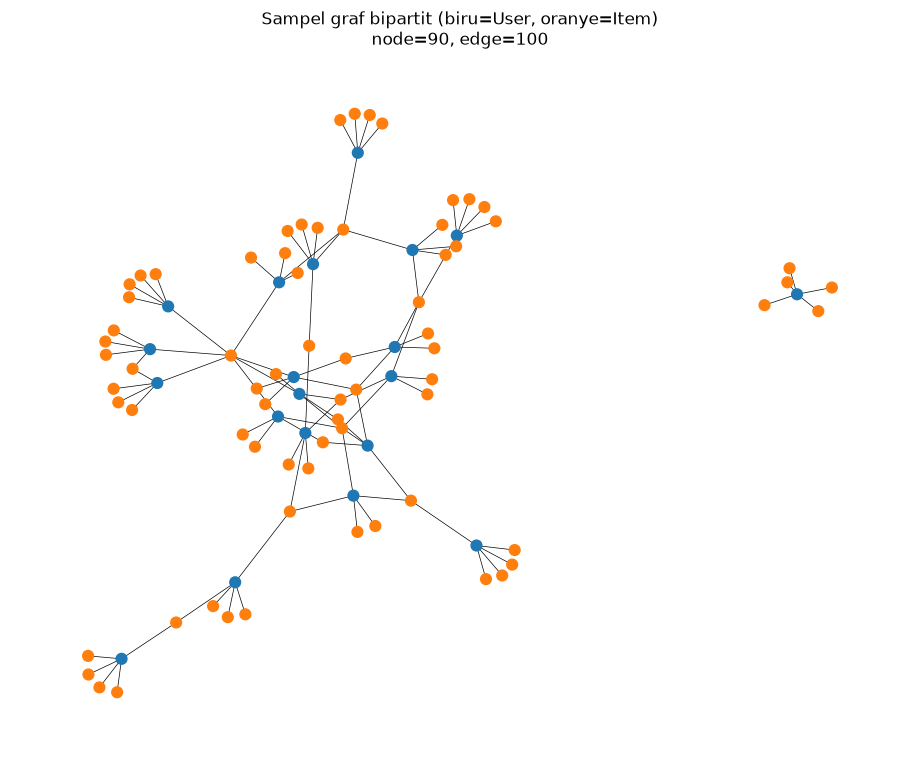

In [12]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_sample(M, n=20, per=5, title=""):
    top = np.argsort(-M.getnnz(axis=1))[:n]
    G = nx.Graph()
    for a in top:
        for b in M[a].nonzero()[1][:per]:
            G.add_edge(f"U{a}", f"I{b}")
    colors = ["tab:blue" if x.startswith("U") else "tab:orange" for x in G.nodes]
    plt.figure(figsize=(9, 7))
    nx.draw_spring(G, node_color=colors, node_size=60, width=0.5, with_labels=False)
    plt.title(f"{title}\nnode={G.number_of_nodes()}, edge={G.number_of_edges()}")
    plt.show()

plot_sample(M, title="Sampel graf bipartit (biru=User, oranye=Item)")

Pada sampel ini, 20 user dengan interaksi terbanyak terhubung ke 70 item (90 simpul, 100 relasi). Karena 100 relasi hanya menjangkau 70 item, sebagian item disentuh lebih dari satu user dan menjadi penghubung antar user, sehingga sebagian besar simpul membentuk satu komponen terhubung, sedangkan satu user terpisah karena item-itemnya tidak dibagi dengan user lain dalam sampel. Karena sampel hanya memuat user paling aktif dan dibatasi 5 item per user, plot ini bias dan tidak mewakili data sebenarnya, di mana 80,5% user hanya berinteraksi dengan satu item.

#### Plot networkx: Sampel dari Sisi Item

Plot ini memakai sudut pandang item: **20 item dengan pengguna terbanyak**, masing-masing dengan maksimal 5 pengguna. Oranye adalah `Item` dan biru adalah `User`. Item populer tampil sebagai simpul pusat yang punya banyak sambungan ke pengguna, sedangkan setiap pengguna di sampel umumnya hanya terhubung ke satu item. Ini sejalan dengan karakteristik VSM Item: vektor item (rata-rata 6,64 pengguna, maksimum 1.831) jauh lebih kaya daripada vektor user (rata-rata 1,50 item). Seperti plot sisi user, ini hanya sampel kecil, bukan seluruh graf.

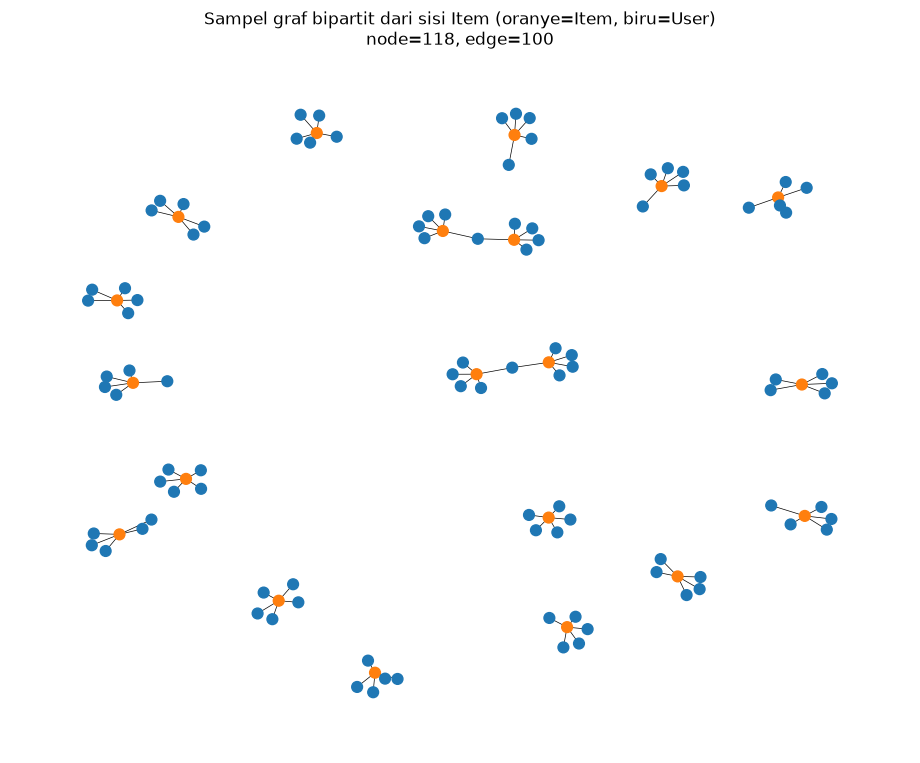

In [6]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_sample_item(MT, n=20, per=5, title=""):
    top = np.argsort(-MT.getnnz(axis=1))[:n]      # 20 item dengan user terbanyak
    G = nx.Graph()
    for a in top:
        for b in MT[a].nonzero()[1][:per]:
            G.add_edge(f"I{a}", f"U{b}")
    colors = ["tab:orange" if x.startswith("I") else "tab:blue" for x in G.nodes]
    plt.figure(figsize=(9, 7))
    nx.draw_spring(G, node_color=colors, node_size=60, width=0.5, with_labels=False)
    plt.title(f"{title}\nnode={G.number_of_nodes()}, edge={G.number_of_edges()}")
    plt.show()

plot_sample_item(MT, title="Sampel graf bipartit dari sisi Item (oranye=Item, biru=User)")

Pada sampel ini, 20 item terhubung ke 98 pengguna (118 simpul, 100 relasi). Hampir semua pengguna hanya terhubung ke satu item, dan hanya dua pengguna yang menjadi penghubung antar dua item. Hal ini konsisten dengan karakteristik data yang sangat jarang. Karena sampel dibatasi 5 pengguna per item, jumlah sambungan tiap item tampak seragam, sehingga plot tidak menggambarkan popularitas sebenarnya (maksimum 1.831 pengguna per item).

### No. 6: Perbandingan Proyeksi (User-User vs Item-Item)

In [19]:
nu, ni = M.shape
print("Proyeksi user-user :", nu, "x", nu, "=", f"{nu*nu:.3e}", "sel")
print("Proyeksi item-item :", ni, "x", ni, "=", f"{ni*ni:.3e}", "sel")
print("Rasio user-user / item-item:", (nu*nu) / (ni*ni))

print("Memori jika dense (GB) user-user:", nu*nu*8/1e9)
print("Memori jika dense (GB) item-item:", ni*ni*8/1e9)

print("Rata-rata interaksi per user:", M.getnnz(axis=1).mean())
print("Rata-rata interaksi per item:", MT.getnnz(axis=1).mean())

Proyeksi user-user : 817398 x 817398 = 6.681e+11 sel
Proyeksi item-item : 184978 x 184978 = 3.422e+10 sel
Rasio user-user / item-item: 19.526615854088245
Memori jika dense (GB) user-user: 5345.115923232
Memori jika dense (GB) item-item: 273.734883872
Rata-rata interaksi per user: 1.5022278008999288
Rata-rata interaksi per item: 6.63818400025949


#### Kesimpulan No. 6

| | Proyeksi user-user | Proyeksi item-item |
|---|---|---|
| Ukuran matriks similarity | 817.398² = 6,68 × 10¹¹ sel | 184.978² = 3,42 × 10¹⁰ sel |
| Memori jika dense | 5.345 GB | 274 GB |
| Rata-rata interaksi per vektor | 1,50 | 6,64 |

Proyeksi **item-item lebih baik**, baik dari sisi efisiensi maupun efektivitas.

- **Efisien.** Matriks similarity item-item **19,5 kali lebih kecil** daripada user-user. Keduanya tidak mungkin disimpan penuh dalam bentuk dense, sehingga similarity dihitung per vektor acuan (satu item terhadap semua item), dan untuk item-item jauh lebih ringan.
- **Efektif.** Satu item rata-rata disentuh 6,64 user, sedangkan satu user hanya berinteraksi dengan 1,50 item (median 1). Vektor user terlalu pendek sehingga cosine antar user nyaris selalu 0 atau 1. Vektor item membawa sinyal lebih banyak.
- **Stabil.** Profil sebuah item (siapa yang melihat atau membelinya) berubah lebih lambat daripada perilaku seorang pengunjung.

Berdasarkan analisis ini, similarity pada no. 7 dihitung pada **proyeksi item-item**.

### No. 7: Similarity Item-Item (Cosine)

In [17]:
from sklearn.metrics.pairwise import cosine_similarity

# item acuan: item dengan jumlah user terbanyak
nnz_item = MT.getnnz(axis=1)
ref = int(np.argmax(nnz_item))
ref_id = int(items[ref])
print("Item acuan:", ref_id, "| jumlah user:", nnz_item[ref])

sims = cosine_similarity(MT[ref], MT).ravel()
sims[ref] = -1                      # buang diri sendiri
top5 = np.argsort(-sims)[:5]

pairs = [{"a": ref_id, "b": int(items[j]), "score": float(sims[j])} for j in top5]
pd.DataFrame(pairs)

Item acuan: 5411 | jumlah user: 1831


,a,b,score
0,5411,33030,0.158991
1,5411,37807,0.109707
2,5411,33956,0.106206
3,5411,256242,0.088480
4,5411,459936,0.084773


#### Interpretasi: Similarity Item-Item (Cosine)

Similarity dihitung dengan **cosine** antara vektor item acuan dan vektor semua item lain (kolom matriks $M$):

$$\cos(a,b)=\frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$$

Cosine dipilih karena hanya mengukur arah vektor, tidak panjangnya, sehingga item populer tidak otomatis menang hanya karena jumlah penggunanya besar. Nilainya 0 (tidak ada pengunjung yang sama) sampai 1 (profil pengunjung identik).

Item acuan adalah **5411**, item dengan pengunjung terbanyak (1.831 user), sehingga datanya paling kaya.

| Peringkat | Item mirip | Cosine |
|---|---|---|
| 1 | 33030 | 0,1590 |
| 2 | 37807 | 0,1097 |
| 3 | 33956 | 0,1062 |
| 4 | 256242 | 0,0885 |
| 5 | 459936 | 0,0848 |

Skor tertinggi hanya **0,159**. Itu wajar karena matriks sangat jarang (density 8,12 × 10⁻⁶) dan item 5411 punya banyak pengunjung, sehingga irisan pengunjungnya dengan item lain kecil dibanding total pengunjungnya. Skor ini bermakna untuk **peringkat relatif**, bukan sebagai ukuran kemiripan mutlak.

#### 7a: Cypher 5 Record dengan Similarity Tertinggi

~~~cypher
MATCH (a:Item {itemId: 5411})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS similarity
ORDER BY s.score DESC
LIMIT 5
~~~

`MATCH` mencari relasi `SIMILAR_TO` dari item acuan 5411, `RETURN` menampilkan pasangan item beserta skornya, `ORDER BY ... DESC` mengurutkan dari yang paling mirip, dan `LIMIT 5` mengambil 5 teratas.

In [28]:
rows, _, _ = driver.execute_query("""
MATCH (a:Item {itemId: 5411})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS similarity
ORDER BY s.score DESC
LIMIT 5
""", database_=DB)

df_sim = pd.DataFrame([dict(r) for r in rows])
df_sim

,acuan,mirip,similarity
0,5411,33030,0.158991
1,5411,37807,0.109707
2,5411,33956,0.106206
3,5411,256242,0.088480
4,5411,459936,0.084773


**Hasil 7a.** Query membaca balik dari Neo4j (bukan dari variabel Python) lima item paling mirip dengan 5411 beserta skornya. Urutan dan skornya sama dengan hasil perhitungan di Python, sehingga terbukti nilai similarity benar-benar tersimpan di graf.

#### 7b: Menuliskan Kembali Similarity ke Graf

Lima pasangan item dengan similarity tertinggi (`pairs`, hasil cosine dari Python) disimpan sebagai relasi baru `SIMILAR_TO` dengan properti `score`:

~~~cypher
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
~~~

`UNWIND` memecah list `pairs` menjadi baris, `MATCH` menemukan dua node `Item`, `MERGE` membuat relasi tanpa duplikat (aman dijalankan ulang), dan `SET` menyimpan skor cosine sebagai properti relasi. Relasi bertambah tepat 5, yaitu total relasi graf naik dari 1.573.886 menjadi 1.573.891.

In [19]:
driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
""", rows=pairs, database_=DB)
print("SIMILAR_TO ditulis:", len(pairs))

SIMILAR_TO ditulis: 5


### No. 8: Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

Kondisi graf dibandingkan pada enam item: item acuan 5411 dan lima item kandidat paling mirip (33030, 37807, 33956, 256242, 459936). Query dijalankan dari Python, lalu hasilnya digambar dengan `networkx`.

#### Sebelum

Relasi `SIMILAR_TO` dikosongkan terlebih dahulu agar kondisi awal bisa ditunjukkan. Jumlah relasi dihitung dengan:

~~~cypher
MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah
~~~

Relasi antar enam item diambil dengan:

~~~cypher
MATCH (i:Item) WHERE i.itemId IN $ids
OPTIONAL MATCH (i)-[s:SIMILAR_TO]->(j:Item)
RETURN i.itemId AS asal, j.itemId AS tujuan, s.score AS similarity
~~~

`OPTIONAL MATCH` dipakai agar item tetap muncul walaupun belum punya relasi `SIMILAR_TO` (kolom `tujuan` dan `similarity` berisi `None`).

In [20]:
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

ids = [5411, 33030, 37807, 33956, 256242, 459936]

def ambil_data():
    rows, _, _ = driver.execute_query("""
    MATCH (i:Item) WHERE i.itemId IN $ids
    OPTIONAL MATCH (i)-[s:SIMILAR_TO]->(j:Item)
    RETURN i.itemId AS asal, j.itemId AS tujuan, s.score AS similarity
    """, ids=ids, database_=DB)
    return pd.DataFrame([dict(r) for r in rows])

def hitung_similar():
    rows, _, _ = driver.execute_query(
        "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah", database_=DB)
    return rows[0]["jumlah"]

def gambar(df, judul):
    G = nx.DiGraph()
    G.add_nodes_from(ids)
    for _, r in df.dropna(subset=["tujuan"]).iterrows():
        G.add_edge(int(r.asal), int(r.tujuan), score=round(r.similarity, 3))
    pos = nx.shell_layout(G, nlist=[[5411], ids[1:]])
    warna = ["tab:red" if n == 5411 else "lightgreen" for n in G.nodes]
    plt.figure(figsize=(7, 6))
    nx.draw(G, pos, with_labels=True, node_color=warna, node_size=1100, font_size=8)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "score"), font_size=8)
    plt.title(judul)
    plt.show()

#### kondisi sebelum

SIMILAR_TO sebelum: 0


,asal,tujuan,similarity
0,5411,None,None
1,33030,None,None
2,37807,None,None
3,33956,None,None
4,256242,None,None
5,459936,None,None


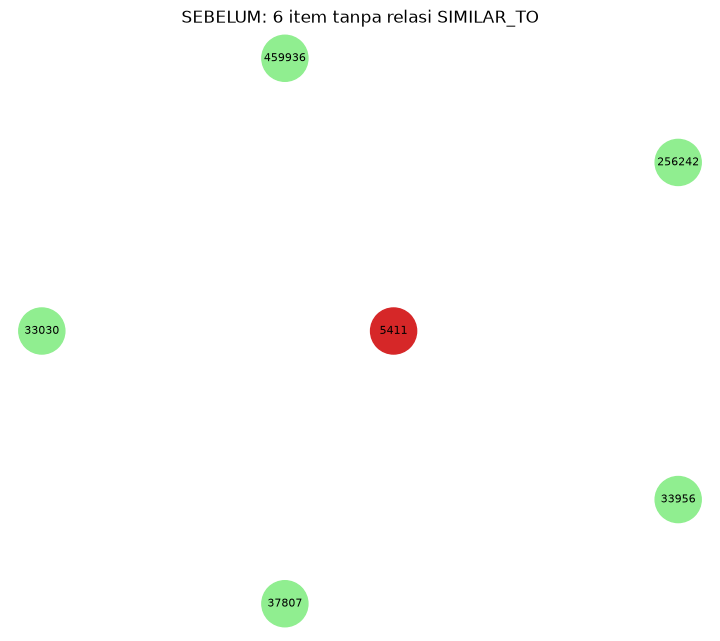

In [21]:
# kosongkan SIMILAR_TO supaya kondisi "sebelum" bisa ditunjukkan lagi
driver.execute_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s", database_=DB)

print("SIMILAR_TO sebelum:", hitung_similar())     # 0
df_sebelum = ambil_data()
display(df_sebelum)
gambar(df_sebelum, "SEBELUM: 6 item tanpa relasi SIMILAR_TO")

#### kondisi sesudah

SIMILAR_TO sesudah: 5


,asal,tujuan,similarity
3,5411,33030.0,0.158991
0,5411,37807.0,0.109707
4,5411,33956.0,0.106206
2,5411,256242.0,0.088480
1,5411,459936.0,0.084773


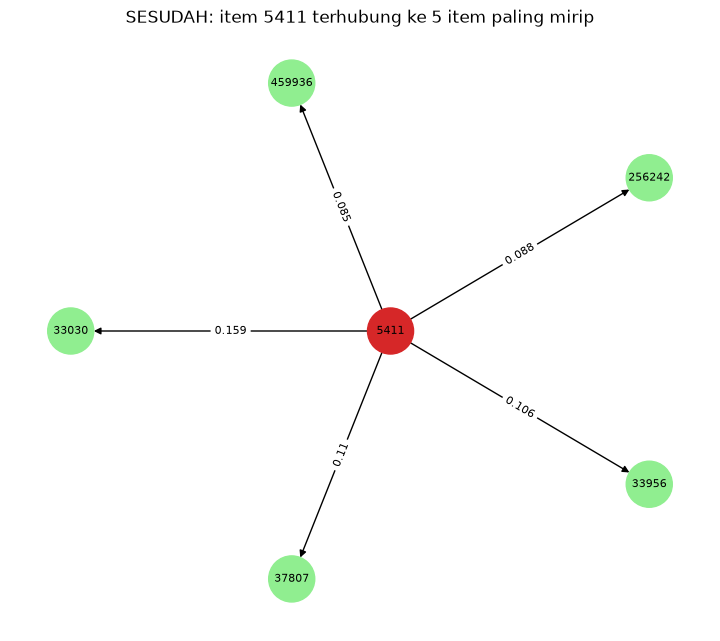

In [22]:
driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
""", rows=pairs, database_=DB)

print("SIMILAR_TO sesudah:", hitung_similar())     # 5
df_sesudah = ambil_data().dropna(subset=["tujuan"]).sort_values("similarity", ascending=False)
display(df_sesudah)
gambar(ambil_data(), "SESUDAH: item 5411 terhubung ke 5 item paling mirip")

#### Interpretasi: Sebelum dan Sesudah Perhitungan Similarity

| Aspek | Sebelum | Sesudah |
|---|---|---|
| Jumlah relasi `SIMILAR_TO` | 0 | 5 |
| Total relasi graf | 1.573.886 | 1.573.891 |
| Hubungan antar 6 item | Tidak ada, setiap item berdiri sendiri | Item 5411 terhubung ke 5 item lain |
| Properti relasi | Tidak ada | `score` (cosine similarity) |
| Bentuk graf | 6 simpul terpisah | Bintang berarah dengan 5411 di pusat |

**Sebelum.** Graf hanya memuat relasi perilaku antara `Visitor` dan `Item` (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`). Tidak ada relasi langsung antar `Item`, sehingga enam item yang diamati tidak saling terhubung. Pada gambar sebelum, keenam simpul berdiri tanpa panah, dan tabel hasil query berisi `None` pada kolom `tujuan` dan `similarity`.

**Sesudah.** Cosine similarity item-item dihitung dari proyeksi item (kolom matriks user × item), lalu lima nilai tertinggi untuk item acuan 5411 ditulis ke graf sebagai relasi `SIMILAR_TO`. Hubungan yang semula hanya tersirat lewat kesamaan pengunjung kini menjadi relasi eksplisit antar item. Total relasi bertambah tepat 5.

**Urutan kemiripan.** Item 33030 paling mirip dengan 5411 (0,159), diikuti 37807 (0,110), 33956 (0,106), 256242 (0,088), dan 459936 (0,085). Item yang berada di urutan teratas adalah item yang paling sering dilihat atau dibeli oleh pengunjung yang sama dengan pengunjung item 5411.

**Skor yang kecil.** Nilai tertinggi hanya 0,159 karena matriks sangat jarang (density sekitar 8,1 × 10⁻⁶) dan satu item rata-rata hanya disentuh 6,64 pengunjung. Item acuan 5411 memiliki 1.831 pengunjung, jauh di atas rata-rata, sehingga irisan pengunjungnya dengan item lain kecil dibanding total pengunjungnya. Skor ini tetap bermakna secara relatif untuk menyusun peringkat, tetapi bukan ukuran kemiripan mutlak.

**Arah relasi.** `SIMILAR_TO` ditulis berarah dari 5411 ke item lain, padahal cosine bersifat simetris. Untuk query dua arah, relasi balik dapat ditambahkan atau query ditulis tanpa arah.

**Manfaat.** Relasi `SIMILAR_TO` dapat langsung dipakai sebagai dasar rekomendasi berbasis item: pengunjung yang melihat item 5411 dapat direkomendasikan 33030, 37807, dan seterusnya. Karena disimpan di graf, rekomendasi dapat diambil dengan satu query Cypher tanpa menghitung ulang di Python.

## 2.2 Analytics

### No. 1: Pemilihan User Acak (Reproducible)

**Proses acak:** user dipilih dengan `numpy.random.default_rng(seed=42)`. Seed tetap membuat user yang sama terpilih setiap kali kode dijalankan, sehingga hasilnya bisa direproduksi.

**Populasi yang diacak.** Tidak semua user layak dipilih. Syaratnya:
1. User ada di matriks P1 dengan minimal 3 item, supaya punya profil untuk dibandingkan.
2. User punya interaksi di P2 pada **item baru**, yaitu item yang dikenal di P1 tetapi belum pernah ia sentuh di P1. Item ini menjadi *ground truth*.

User tanpa ground truth tidak bisa dievaluasi, dan item yang sudah ia lihat di P1 tidak mungkin muncul sebagai rekomendasi, sehingga dikeluarkan dari ground truth.

In [23]:
SEED = 42
rng = np.random.default_rng(SEED)

p2 = pd.read_csv("data/events_p2.csv")

users_set = set(int(u) for u in users)
items_set = set(int(i) for i in items)
uid2row = {int(u): r for r, u in enumerate(users)}
n_per_user = M.getnnz(axis=1)

# P2 dibatasi ke user dan item yang dikenal di P1
p2_ok = p2[p2.visitorid.isin(users_set) & p2.itemid.isin(items_set)]
gt_all = p2_ok.groupby("visitorid").itemid.apply(lambda s: set(int(x) for x in s))

# ground truth = item P2 yang BELUM pernah disentuh user di P1
eligible, gt_user = [], {}
for u, g in gt_all.items():
    r = uid2row[int(u)]
    if n_per_user[r] < 3:
        continue
    seen_ids = {int(items[j]) for j in M.indices[M.indptr[r]:M.indptr[r + 1]]}
    g_baru = g - seen_ids
    if g_baru:
        eligible.append(int(u))
        gt_user[int(u)] = g_baru
eligible = sorted(eligible)

target = int(rng.choice(eligible))

print("Jumlah kandidat user:", len(eligible))
print("User terpilih:", target, "| seed:", SEED)
print("Jumlah item di P1:", n_per_user[uid2row[target]])
print("Ground truth P2 (item baru):", gt_user[target])

Jumlah kandidat user: 4300
User terpilih: 131204 | seed: 42
Jumlah item di P1: 3
Ground truth P2 (item baru): {241441, 441668}


#### Interpretasi: User Terpilih

| Besaran | Nilai |
|---|---|
| Kandidat user yang memenuhi syarat | 4.300 |
| User terpilih (seed 42) | 131204 |
| Item di P1 | 3 |
| Ground truth P2 (item baru) | 241441, 441668 |

Dari 22.142 user yang muncul di kedua periode, hanya **4.300** yang memenuhi syarat (minimal 3 item di P1 dan punya item baru di P2). Penyaringan ini perlu agar setiap user punya profil dan ground truth yang bisa dievaluasi. Karena memakai `default_rng(42)`, user yang sama terpilih setiap kali kode dijalankan.

### No. 1a: Script KNN (User-Based Collaborative Filtering, k = 5)

**Langkah:**
1. Tiap user direpresentasikan sebagai vektor baris matriks $M$ (user × item) dengan bobot `view` = 1, `addtocart` = 3, `transaction` = 5.
2. Kemiripan user target dengan semua user lain dihitung dengan **cosine similarity**. Vektor user dinormalisasi lebih dulu sehingga *dot product* sama dengan cosine.
3. Diambil $k = 5$ **tetangga terdekat** (cosine tertinggi).
4. Skor tiap item untuk user target:

$$\text{skor}(i) = \sum_{v \in N_k(u)} \text{sim}(u,v)\cdot M_{v,i}$$

5. Item yang sudah pernah disentuh user target di P1 dibuang, lalu item diurutkan dari skor tertinggi. **Top-5** menjadi daftar rekomendasi.

**Catatan desain:**
- Tetangga hanya dipilih dari user yang punya minimal satu item yang belum disentuh user target. Tetangga yang itemnya identik tidak punya apa pun untuk direkomendasikan.
- Jika item dari tetangga kurang dari 5, sisanya diisi item terpopuler dan diberi label `popularitas` pada tabel.ngsi KNN

In [24]:
from sklearn.preprocessing import normalize

Mn = normalize(M, norm="l2", axis=1).tocsr()        # vektor user dinormalisasi, dot product = cosine
Mbin = (M > 0).astype(np.int32).tocsr()
popularitas = M.getnnz(axis=0)                      # jumlah user per item

def recommend(target_id, K=5, n_rec=5):
    t = uid2row[int(target_id)]

    sims = Mn.dot(Mn[t].T).toarray().ravel()        # cosine ke semua user
    overlap = Mbin.dot(Mbin[t].T).toarray().ravel() # jumlah item yang sama dengan target
    sims[(n_per_user - overlap) <= 0] = -1          # tetangga harus membawa item baru (target sendiri ikut terbuang)

    nbrs = np.argpartition(-sims, K)[:K]
    nbrs = nbrs[np.argsort(-sims[nbrs])]
    nbrs = nbrs[sims[nbrs] > 0]

    scores = np.asarray(M[nbrs].T.dot(sims[nbrs])).ravel()
    seen = M[t].indices
    scores[seen] = 0                                # buang item yang sudah disentuh

    order = [j for j in np.argsort(-scores)[:n_rec] if scores[j] > 0]
    rec = [(int(items[j]), float(scores[j]), "KNN") for j in order]

    if len(rec) < n_rec:                            # cadangan: item terpopuler
        sudah = set(seen.tolist()) | set(int(j) for j in order)
        for j in np.argsort(-popularitas):
            if len(rec) == n_rec:
                break
            if int(j) not in sudah:
                rec.append((int(items[j]), 0.0, "popularitas"))
    return nbrs, sims[nbrs], rec

### No. 1b: Tiga Item yang Diiklankan (k = 5)

Fungsi `recommend` dijalankan untuk user terpilih dengan $k = 5$. Lima item teratas menjadi daftar rekomendasi (dipakai pada Hit@5 dan NDCG@5), dan **tiga item teratas** ditampilkan sebagai item yang diiklankan.

In [25]:
nbrs, nbr_sims, rec = recommend(target, K=5)

df_nbr = pd.DataFrame({
    "tetangga (visitorId)": [int(users[n]) for n in nbrs],
    "cosine": nbr_sims.round(4),
    "jumlah item": n_per_user[nbrs],
})
df_nbr.index = range(1, len(df_nbr) + 1)
print("User target:", target)
display(df_nbr)

df_rec = pd.DataFrame(rec, columns=["itemId", "skor", "sumber"])
df_rec.index = range(1, len(df_rec) + 1)
df_rec.index.name = "rank"
print("Top-5 rekomendasi:")
display(df_rec)

ads = [r[0] for r in rec[:3]]
print("3 item yang diiklankan:", ads)

User target: 131204


,tetangga (visitorId),cosine,jumlah item
1,632016,0.4082,4
2,1239903,0.3333,3
3,652658,0.2887,2
4,1219879,0.2357,3
5,793374,0.0640,3


Top-5 rekomendasi:


,itemId,skor,sumber
rank,,,
1,441472,0.666667,KNN
2,386126,0.575577,KNN
3,313722,0.575577,KNN
4,355834,0.408248,KNN
5,285732,0.408248,KNN


3 item yang diiklankan: [441472, 386126, 313722]


#### Interpretasi: Hasil KNN

**Tetangga terdekat** (user target 131204):

| Tetangga | Cosine | Jumlah item |
|---|---|---|
| 632016 | 0,4082 | 4 |
| 1239903 | 0,3333 | 3 |
| 652658 | 0,2887 | 2 |
| 1219879 | 0,2357 | 3 |
| 793374 | 0,0640 | 3 |

**Rekomendasi top-5** (semua bersumber dari KNN, tidak ada tambalan `popularitas`):

| Rank | Item | Skor |
|---|---|---|
| 1 | 441472 | 0,6667 |
| 2 | 386126 | 0,5756 |
| 3 | 313722 | 0,5756 |
| 4 | 355834 | 0,4082 |
| 5 | 285732 | 0,4082 |

**Tiga item yang diiklankan:** **441472, 386126, 313722**.

- Kemiripan tetangga tergolong sedang: empat tetangga teratas bercosine di atas 0,23, tetapi tetangga kelima hanya **0,064**, sehingga kontribusinya lemah. Ini akibat user target hanya punya 3 item dan sebagian besar user lain tidak berbagi item dengannya.
- Skor item merupakan jumlah (cosine tetangga × bobot interaksi tetangga). Item yang disentuh tetangga dengan cosine tinggi dan bobot besar (misalnya `addtocart` atau `transaction`) naik ke peringkat atas.
- Peringkat 2–3 dan 4–5 memiliki skor sama, sehingga urutan di antara keduanya mengikuti urutan indeks item.

### No. 2: Evaluasi Rekomendasi (Hit@5 dan NDCG@5)

**Ground truth:** item P2 yang diinteraksi user target dan belum pernah ia sentuh di P1. Relevansi bersifat biner: item rekomendasi bernilai 1 jika ada di ground truth, selain itu 0.

**(a) Hit@5.** Bernilai 1 jika minimal satu dari 5 item rekomendasi ada di ground truth, selain itu 0.

$$\text{Hit@5} = \mathbb{1}\left[\sum_{i=1}^{5} rel_i \ge 1\right]$$

**(b) NDCG@5.** Menilai hit sekaligus posisinya, karena hit di peringkat atas bernilai lebih tinggi.

$$\text{DCG@5} = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i+1)}, \qquad \text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

IDCG@5 adalah DCG pada urutan ideal, yaitu semua item relevan berada di peringkat teratas (maksimal $\min(|\text{ground truth}|, 5)$ item).

In [26]:
gt = gt_user[target]
rekomendasi = [r[0] for r in rec]                 # top-5
rel = [1 if i in gt else 0 for i in rekomendasi]

hit5 = int(any(rel))
dcg = sum(r / np.log2(k + 2) for k, r in enumerate(rel))           # k mulai 0, jadi log2(k+2)
idcg = sum(1 / np.log2(k + 2) for k in range(min(len(gt), 5)))
ndcg5 = dcg / idcg if idcg > 0 else 0.0

print("Rekomendasi top-5 :", rekomendasi)
print("Ground truth P2   :", gt)
print("Relevansi (rel)   :", rel)
print(f"DCG@5  = {dcg:.4f} | IDCG@5 = {idcg:.4f}")
print(f"Hit@5  = {hit5}")
print(f"NDCG@5 = {ndcg5:.4f}")

Rekomendasi top-5 : [441472, 386126, 313722, 355834, 285732]
Ground truth P2   : {241441, 441668}
Relevansi (rel)   : [0, 0, 0, 0, 0]
DCG@5  = 0.0000 | IDCG@5 = 1.6309
Hit@5  = 0
NDCG@5 = 0.0000


#### Interpretasi: Hit@5 dan NDCG@5

| Besaran | Nilai |
|---|---|
| Rekomendasi top-5 | 441472, 386126, 313722, 355834, 285732 |
| Ground truth P2 | 241441, 441668 |
| Relevansi | 0, 0, 0, 0, 0 |
| DCG@5 | 0,0000 |
| IDCG@5 | 1,6309 |
| **Hit@5** | **0** |
| **NDCG@5** | **0,0000** |

**Hit@5 = 0** karena tidak ada satu pun dari lima item rekomendasi yang termasuk ground truth (241441 dan 441668). Akibatnya DCG = 0 dan NDCG@5 = 0. IDCG@5 = 1,6309 adalah nilai ideal bila kedua item relevan ada di peringkat 1 dan 2 ($1 + 1/\log_2 3$).

Kegagalan pada user ini dapat dijelaskan oleh beberapa faktor:
- **Profil terlalu pendek.** User hanya punya 3 item di P1, sehingga sinyal untuk mencari tetangga lemah.
- **Ground truth berupa item baru.** Metrik menuntut sistem menebak item yang belum pernah disentuh user dari antara ±185 ribu item. Peluang kebetulan (acak) sangat kecil, hanya sekitar 0,003% per item relevan.
- **Tetangga terbatas.** Tetangga hanya membawa 2–4 item, sehingga kandidat rekomendasi sangat sedikit.

Hasil ini berasal dari **satu user**, sehingga Hit@5 hanya bisa 0 atau 1 dan sangat bergantung pada user yang terpilih. Karena itu dilakukan evaluasi tambahan pada banyak user.

#### Evaluasi Tambahan: 200 User Acak

Prosedur yang sama (KNN $k=5$, top-5, ground truth item baru di P2) dijalankan pada **200 user** acak (seed 42) dari 4.300 kandidat, lalu Hit@5 dan NDCG@5 dirata-ratakan. Evaluasi ini melengkapi hasil satu user di atas dan lebih mewakili kinerja sistem.

In [27]:
from tqdm import tqdm

N_EVAL = 200
rng_eval = np.random.default_rng(SEED)
sample = rng_eval.choice(eligible, size=N_EVAL, replace=False)

hits, ndcgs = [], []
for u in tqdm(sample):
    _, _, r = recommend(u, K=5)
    g = gt_user[int(u)]
    rl = [1 if x[0] in g else 0 for x in r]
    d = sum(v / np.log2(k + 2) for k, v in enumerate(rl))
    ideal = sum(1 / np.log2(k + 2) for k in range(min(len(g), 5)))
    hits.append(int(any(rl)))
    ndcgs.append(d / ideal if ideal > 0 else 0.0)

print(f"Rata-rata Hit@5  ({N_EVAL} user): {np.mean(hits):.4f}")
print(f"Rata-rata NDCG@5 ({N_EVAL} user): {np.mean(ndcgs):.4f}")

100%|██████████| 200/200 [00:11<00:00, 17.10it/s]

Rata-rata Hit@5  (200 user): 0.0300
Rata-rata NDCG@5 (200 user): 0.0159


#### Interpretasi: Evaluasi 200 User

| Metrik | Rata-rata (200 user) |
|---|---|
| Hit@5 | 0,0300 |
| NDCG@5 | 0,0159 |

- **Hit@5 = 0,03.** Sekitar 6 dari 200 user (3%) mendapat minimal satu item yang benar di top-5. Angka ini kecil, tetapi jauh di atas peluang acak, karena sistem harus menebak item baru dari ±185 ribu item.
- **NDCG@5 (0,0159) lebih kecil daripada Hit@5.** Hit yang terjadi tidak selalu berada di peringkat teratas, dan sebagian user punya beberapa item ground truth sehingga IDCG-nya lebih besar.
- **Hasil satu user (0) konsisten dengan rata-rata.** User terpilih termasuk 97% user yang tidak mendapat hit.
- **Penyebab nilai rendah** adalah karakter data: sangat jarang (density 8,12 × 10⁻⁶), 80,5% user hanya punya satu item, jendela P2 hanya 34 hari, dan evaluasi menuntut menebak *item baru*. Ini umum pada data *implicit feedback* ritel online dengan pembagian temporal.

## Kesimpulan dan Keterbatasan

**Kesimpulan**
1. Data RetailRocket difilter menjadi P1 (1 Juni – 15 Agustus 2015) sebagai data latih dan P2 (16 Agustus – 18 September 2015) sebagai data uji, lalu P1 diimpor ke Neo4j (817.398 `Visitor`, 184.978 `Item`, 1.573.886 relasi).
2. Matriks user × item sangat jarang (density 8,12 × 10⁻⁶). Proyeksi **item-item** dipilih karena 19,5 kali lebih kecil dan vektor item (rata-rata 6,64 interaksi) lebih kaya daripada vektor user (rata-rata 1,50).
3. Similarity cosine item-item berhasil dihitung dan ditulis kembali ke graf sebagai relasi `SIMILAR_TO` (0 menjadi 5 relasi).
4. KNN user-based ($k=5$) menghasilkan rekomendasi untuk user 131204 dengan item iklan 441472, 386126, dan 313722. Pada user ini Hit@5 = 0 dan NDCG@5 = 0. Pada 200 user, Hit@5 = 0,0300 dan NDCG@5 = 0,0159.

**Keterbatasan dan saran**
- Evaluasi memakai satu pembagian waktu dan hanya user yang muncul di kedua periode (4.300 dari 817.398), sehingga hasil tidak mewakili pengunjung baru (*cold-start*).
- Pembobotan 1/3/5 ditetapkan manual dan belum dioptimalkan.
- Belum ada pembanding (*baseline*) seperti rekomendasi item terpopuler. Dengan pembanding, nilai Hit@5 dan NDCG@5 dapat dinilai lebih adil.
- Perbaikan yang mungkin: KNN berbasis item memakai proyeksi item-item dari no. 7, kombinasi dengan popularitas (*hybrid*) untuk user berprofil pendek, dan P1 yang lebih panjang atau ground truth yang dibatasi pada `addtocart` dan `transaction`.